In [1]:
# Import the Google Colab drive module to allow mounting Google Drive
from google.colab import drive

# Import pandas for data manipulation and analysis
import pandas as pd

# Mount Google Drive at the standard Colab directory path
drive.mount("/content/drive")

# Define the file path for the downloaded Honduras FAO FPMA CSV file
file_path = "/content/drive/MyDrive/ENSO_project/prices/FPMA_Honduras_Tue_Oct_27_2026.csv"

# Read the CSV file into a pandas DataFrame
df = pd.read_csv(file_path)

# Display the header label before printing original column names
print("Full Column Names:")

# Print the full list of original column names from the dataset
print(list(df.columns))

# Find columns whose names begin with "Honduras, WHOLESALE" to identify the price series
wholesale_cols = [
    c for c in df.columns if c.startswith("Honduras, WHOLESALE")
]

# Map the first wholesale column (red beans) and second (white maize) to target column names
rename_map = {wholesale_cols[0]: "beans_hnl_t", wholesale_cols[1]: "maize_hnl_t"}

# Rename the two price columns in the DataFrame
df = df.rename(columns=rename_map)

# Convert the Date column from MM/DD/YYYY string format to datetime objects
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")

# Sort rows chronologically from oldest to newest and reset the DataFrame index
df = df.sort_values(by="Date").reset_index(drop=True)

# Extract the earliest date in the dataset formatted as YYYY-MM-DD
first_date = df["Date"].min().strftime("%Y-%m-%d")

# Extract the latest date in the dataset formatted as YYYY-MM-DD
last_date = df["Date"].max().strftime("%Y-%m-%d")

# Calculate the total count of monthly observations in the DataFrame
total_months = len(df)

# Extract dates where red beans price values are null/missing
missing_beans_dates = (
    df[df["beans_hnl_t"].isna()]["Date"].dt.strftime("%Y-%m-%d").tolist()
)

# Extract dates where white maize price values are null/missing
missing_maize_dates = (
    df[df["maize_hnl_t"].isna()]["Date"].dt.strftime("%Y-%m-%d").tolist()
)

# Compute the minimum price for red beans, excluding missing values
min_beans = df["beans_hnl_t"].min()

# Compute the maximum price for red beans, excluding missing values
max_beans = df["beans_hnl_t"].max()

# Compute the minimum price for white maize, excluding missing values
min_maize = df["maize_hnl_t"].min()

# Compute the maximum price for white maize, excluding missing values
max_maize = df["maize_hnl_t"].max()

# Display header for summary statistics section
print("\n--- Summary Statistics ---")

# Print the start and end dates of the time series
print(f"First Date: {first_date} | Last Date: {last_date}")

# Print the total number of monthly records
print(f"Number of Months: {total_months}")

# Print dates corresponding to missing red bean price observations
print(
    f"Missing Red Beans Months ({len(missing_beans_dates)} total): {missing_beans_dates}"
)

# Print dates corresponding to missing white maize price observations
print(
    f"Missing White Maize Months ({len(missing_maize_dates)} total): {missing_maize_dates}"
)

# Print minimum and maximum wholesale prices for red beans in HNL/tonne
print(f"Red Beans Price (HNL/t): Min = {min_beans:.2f}, Max = {max_beans:.2f}")

# Print minimum and maximum wholesale prices for white maize in HNL/tonne
print(f"White Maize Price (HNL/t): Min = {min_maize:.2f}, Max = {max_maize:.2f}")

Mounted at /content/drive
Full Column Names:
['iso3_country_code', 'Date', 'Honduras, WHOLESALE, National Average, Beans (red), HNL/tonne', 'Honduras, WHOLESALE, National Average, Maize (white), HNL/tonne']

--- Summary Statistics ---
First Date: 2000-01-01 | Last Date: 2026-08-01
Number of Months: 320
Missing Red Beans Months (8 total): ['2003-01-01', '2007-12-01', '2022-04-01', '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01', '2022-09-01']
Missing White Maize Months (15 total): ['2001-02-01', '2003-01-01', '2007-12-01', '2008-01-01', '2008-02-01', '2008-10-01', '2015-10-01', '2022-04-01', '2022-05-01', '2022-06-01', '2022-07-01', '2022-08-01', '2022-09-01', '2024-12-01', '2025-01-01']
Red Beans Price (HNL/t): Min = 2343.13, Max = 51387.39
White Maize Price (HNL/t): Min = 306.39, Max = 17445.15


--- 5 Lowest Values for Red Beans (HNL/kg) ---
Date: 2003-05-01 | Price: 2.3431 HNL/kg
Date: 2003-04-01 | Price: 2.4985 HNL/kg
Date: 2003-03-01 | Price: 3.6711 HNL/kg
Date: 2003-06-01 | Price: 4.8803 HNL/kg
Date: 2003-09-01 | Price: 5.1586 HNL/kg

--- 5 Lowest Values for White Maize (HNL/kg) ---
Date: 2000-01-01 | Price: 0.3064 HNL/kg
Date: 2003-05-01 | Price: 1.1769 HNL/kg
Date: 2003-03-01 | Price: 1.4710 HNL/kg
Date: 2003-04-01 | Price: 1.4757 HNL/kg
Date: 2003-09-01 | Price: 1.5628 HNL/kg


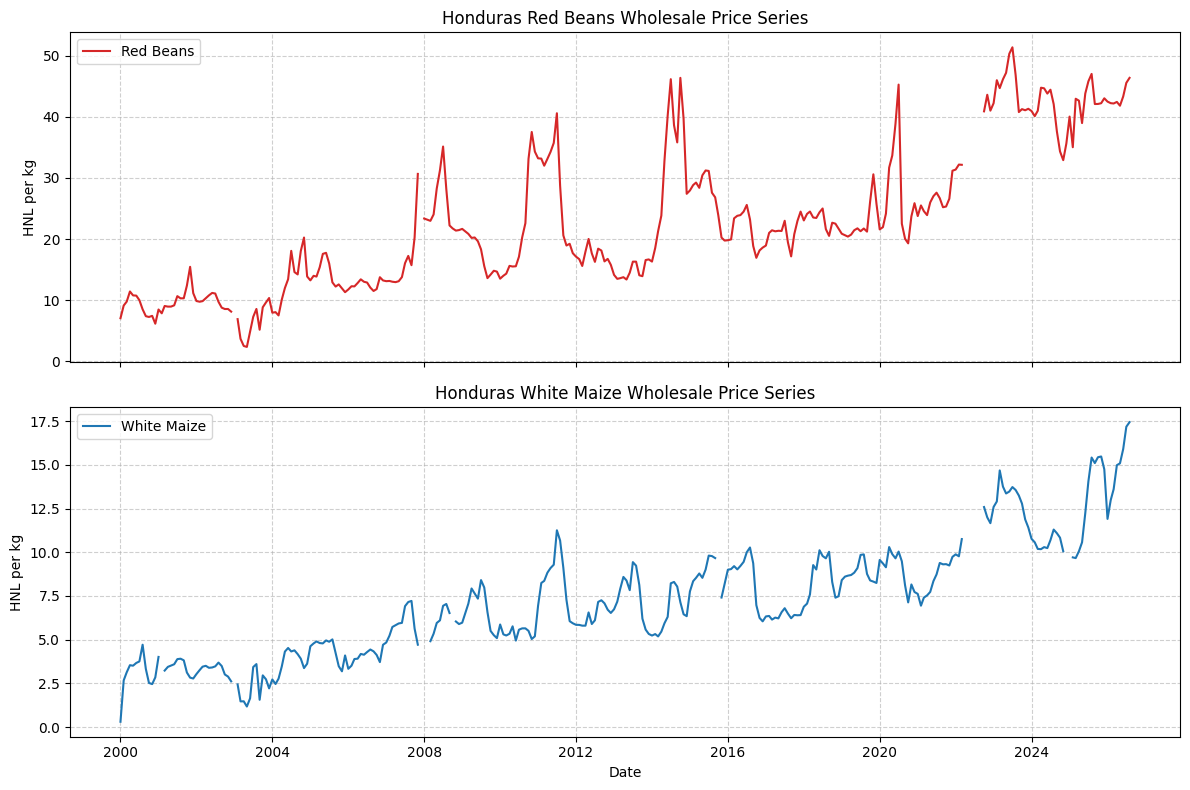

In [2]:
# Import matplotlib.pyplot for plotting time series data
import matplotlib.pyplot as plt

# Create the beans_hnl_kg column by dividing per-tonne bean prices by 1,000
df["beans_hnl_kg"] = df["beans_hnl_t"] / 1000

# Create the maize_hnl_kg column by dividing per-tonne maize prices by 1,000
df["maize_hnl_kg"] = df["maize_hnl_t"] / 1000

# Select the 5 lowest red bean prices per kg along with their corresponding dates
lowest_beans = df.nsmallest(5, "beans_hnl_kg")[["Date", "beans_hnl_kg"]]

# Print header label for the lowest red bean price records
print("--- 5 Lowest Values for Red Beans (HNL/kg) ---")

# Iterate over each row of lowest bean prices and display formatted date and price
for _, row in lowest_beans.iterrows():
    print(
        f"Date: {row['Date'].strftime('%Y-%m-%d')} | Price: {row['beans_hnl_kg']:.4f} HNL/kg"
    )

# Select the 5 lowest white maize prices per kg along with their corresponding dates
lowest_maize = df.nsmallest(5, "maize_hnl_kg")[["Date", "maize_hnl_kg"]]

# Print header label for the lowest white maize price records
print("\n--- 5 Lowest Values for White Maize (HNL/kg) ---")

# Iterate over each row of lowest maize prices and display formatted date and price
for _, row in lowest_maize.iterrows():
    print(
        f"Date: {row['Date'].strftime('%Y-%m-%d')} | Price: {row['maize_hnl_kg']:.4f} HNL/kg"
    )

# Initialize a figure with two vertically stacked subplots sharing the x-axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Plot the red beans price series in the top subplot panel using a red line
ax1.plot(
    df["Date"],
    df["beans_hnl_kg"],
    color="tab:red",
    linewidth=1.5,
    label="Red Beans",
)

# Set the title for the top panel figure
ax1.set_title("Honduras Red Beans Wholesale Price Series")

# Set the y-axis label for the top panel to indicate currency per kilogram
ax1.set_ylabel("HNL per kg")

# Add grid lines to the top panel to make identifying jumps and outliers easier
ax1.grid(True, linestyle="--", alpha=0.6)

# Add a legend to the top panel for series identification
ax1.legend(loc="upper left")

# Plot the white maize price series in the bottom subplot panel using a blue line
ax2.plot(
    df["Date"],
    df["maize_hnl_kg"],
    color="tab:blue",
    linewidth=1.5,
    label="White Maize",
)

# Set the title for the bottom panel figure
ax2.set_title("Honduras White Maize Wholesale Price Series")

# Set the x-axis label on the bottom panel representing time
ax2.set_xlabel("Date")

# Set the y-axis label for the bottom panel to indicate currency per kilogram
ax2.set_ylabel("HNL per kg")

# Add grid lines to the bottom panel to make identifying jumps and outliers easier
ax2.grid(True, linestyle="--", alpha=0.6)

# Add a legend to the bottom panel for series identification
ax2.legend(loc="upper left")

# Optimize spacing between subplots to prevent title and label overlap
plt.tight_layout()

# Render and display the two-panel plot figure
plt.show()